# Kriteria 1 — Fine-tuning LLM dengan QLoRA (Unsloth + SFTTrainer)

**Submission PGABL — Fepriyadi Harahap**

Notebook ini melatih model *text generation* menjadi asisten instruksi berbahasa Indonesia.
Hasilnya di-*push* ke Hugging Face dan dipakai lagi pada tahap GRPO dan RAG.

| Komponen | Pilihan |
|---|---|
| Pre-trained model | `unsloth/Qwen2.5-3B-Instruct` (Qwen2, task Text Generation, didukung Unsloth) |
| Dataset | `Ichsan2895/alpaca-gpt4-indonesian` (instruction tanya–jawab format Alpaca, Bahasa Indonesia) + contoh kerja RAG dari 4 PDF UU/PP (dibuat kode, tanpa teacher model) |
| Chat template | ChatML (`<|im_start|>` / `<|im_end|>`) |
| Teknik | QLoRA: 4-bit NF4 + **double quantization**, LoRA di Multi-Head Attention **dan** Feed Forward Network |
| Trainer | `SFTTrainer` (TRL) — eksperimen hyperparameter, lalu training final **800 steps** dengan validation |
| Output | `model.push_to_hub_merged(..., save_method="merged_16bit")` |

> Jalankan di **Google Colab (GPU T4)** atau **Kaggle (GPU T4/P100)**. Simpan token Hugging Face (akses *write*)
> sebagai secret bernama `HF_TOKEN`.

## 0. Instalasi & Import

In [1]:
%%capture
# Unsloth otomatis memasang versi torch / transformers / trl / peft / bitsandbytes yang saling kompatibel.
# Jika Colab meminta "Restart session" setelah instalasi, lakukan restart lalu lanjutkan dari cell berikutnya.
!pip install -q unsloth
# PDF UU/PP untuk contoh kerja RAG (versi sama dengan notebook RAG agar parent chunk identik)
!pip install -q "langchain-community==0.4.2" "langchain-text-splitters==1.1.3" "pymupdf==1.28.2" "gdown>=5.2.0"

In [2]:
# Unsloth harus di-import sebelum transformers / trl agar patch optimasinya aktif.
from unsloth import FastLanguageModel, is_bfloat16_supported
from unsloth.chat_templates import get_chat_template, train_on_responses_only

import gc
import os
import random
import re
import time
from collections import Counter

import matplotlib.pyplot as plt
import pandas as pd
import torch
from datasets import Dataset, concatenate_datasets, load_dataset
from langchain_community.document_loaders import PyMuPDFLoader
from langchain_core.documents import Document
from langchain_text_splitters import RecursiveCharacterTextSplitter
from transformers import AutoTokenizer, BitsAndBytesConfig, TextStreamer
from trl import SFTConfig, SFTTrainer

🦥 Unsloth: Will patch your computer to enable 2x faster free finetuning.
🦥 Unsloth Zoo will now patch everything to make training faster!


In [3]:
assert torch.cuda.is_available(), "Notebook ini membutuhkan GPU CUDA (Colab T4 / Kaggle T4 / P100)."
gpu = torch.cuda.get_device_properties(0)
GPU_TOTAL_GB = round(gpu.total_memory / 1024**3, 2)
print(f"GPU: {gpu.name} | VRAM: {GPU_TOTAL_GB} GB | bf16 didukung: {is_bfloat16_supported()}")

GPU: Tesla T4 | VRAM: 14.56 GB | bf16 didukung: False


In [4]:
from huggingface_hub import login, whoami


def get_hf_token():
    """Token Hugging Face (akses write) dari Colab Secrets / Kaggle Secrets / env var / input manual."""
    try:
        from google.colab import userdata
        token = userdata.get("HF_TOKEN")
        if token:
            return token
    except Exception:
        pass
    try:
        from kaggle_secrets import UserSecretsClient
        return UserSecretsClient().get_secret("HF_TOKEN")
    except Exception:
        pass
    if os.environ.get("HF_TOKEN"):
        return os.environ["HF_TOKEN"]
    from getpass import getpass
    return getpass("Masukkan Hugging Face token (write): ")


HF_TOKEN = get_hf_token()
login(token=HF_TOKEN)
HF_USERNAME = whoami(token=HF_TOKEN)["name"]
print("Login Hugging Face sebagai:", HF_USERNAME)

Login Hugging Face sebagai: Fepriyadi


In [5]:
BASE_MODEL = "unsloth/Qwen2.5-3B-Instruct"   # arsitektur Qwen2 (didukung Unsloth), task: Text Generation
SFT_REPO = f"{HF_USERNAME}/Qwen2.5-3B-Instruct-Alpaca-ID-SFT"     # hasil Kriteria 1 (SFT)
GRPO_REPO = f"{HF_USERNAME}/Qwen2.5-3B-Instruct-Alpaca-ID-GRPO"   # hasil Kriteria 1 Advanced (GRPO)
SEED = 3407

MAX_SEQ_LENGTH = 3072      # contoh RAG (3 parent chunk + pertanyaan + target) ~2.100 token, maks ~2.500
ALPACA_MAX_TOKENS = 1024   # filter Alpaca tetap sama seperti sebelumnya
SFT_SYSTEM_PROMPT = "Anda adalah asisten AI berbahasa Indonesia yang membantu, jujur, dan menjawab dengan jelas."
print("Base model :", BASE_MODEL)
print("Repo tujuan:", SFT_REPO)

Base model : unsloth/Qwen2.5-3B-Instruct
Repo tujuan: Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT


## 1. Dataset & Mapping ke Chat Template (ChatML)

Dataset `Ichsan2895/alpaca-gpt4-indonesian` **tidak** memakai tiga kolom Alpaca standar
(`instruction`, `input`, `output`). Isinya hanya:

```text
Unnamed: 0   -> nomor baris asli (tidak dipakai)
input        -> instruksi pada baris pertama + konteks opsional pada baris berikutnya
output       -> jawaban (ground truth)
```

Karena itu fungsi mapping memecah `input` menjadi *instruksi* dan *konteks* terlebih dahulu,
lalu menyusun percakapan `system → user → assistant` dan merendernya dengan chat template ChatML
milik Qwen2.5 melalui `datasets.Dataset.map`.

In [6]:
raw_dataset = load_dataset("Ichsan2895/alpaca-gpt4-indonesian", split="train")
print(raw_dataset)
n_with_context = sum("\n" in text.strip() for text in raw_dataset["input"])
print(f"Baris dengan konteks tambahan: {n_with_context} dari {len(raw_dataset)}")

README.md:   0%|          | 0.00/1.91k [00:00<?, ?B/s]

alpaca-gpt4-indonesia.csv: reconstructing file:   0%|          |  0.00B / 41.4MB            

alpaca-gpt4-indonesia.csv: downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/49969 [00:00<?, ? examples/s]

Dataset({
    features: ['Unnamed: 0', 'input', 'output'],
    num_rows: 49969
})
Baris dengan konteks tambahan: 19327 dari 49969


### Contoh satu baris dataset yang **BELUM** di-mapping

In [7]:
raw_dataset[2]

{'Unnamed: 0': 5,
 'input': 'Diberikan deskripsi tentang peristiwa pribadi, tuliskan satu bait sajak haiku.\nBerlayar di laut di hari yang cerah',
 'output': 'Lautan membiru cemerlang\nTerang matahari di atas gemericik air\nSerenitas berenang.'}

In [8]:
# Tokenizer + chat template ChatML (template "qwen-2.5" di Unsloth = ChatML dengan <|im_start|> / <|im_end|>)
tokenizer = get_chat_template(AutoTokenizer.from_pretrained(BASE_MODEL), chat_template="qwen-2.5")


def split_alpaca_input(text):
    """Kolom `input` = instruksi (baris pertama) + konteks opsional (baris berikutnya)."""
    instruction, _, context = text.strip().partition("\n")
    return instruction.strip(), context.strip()


def to_chatml(batch):
    """Mapping batch Alpaca mentah -> teks percakapan ChatML lengkap dengan token spesial."""
    texts = []
    for raw_input, output in zip(batch["input"], batch["output"]):
        instruction, context = split_alpaca_input(raw_input)
        user_content = f"{instruction}\n\nInput:\n{context}" if context else instruction
        messages = [
            {"role": "system", "content": SFT_SYSTEM_PROMPT},
            {"role": "user", "content": user_content},
            {"role": "assistant", "content": output.strip()},
        ]
        texts.append(tokenizer.apply_chat_template(messages, tokenize=False, add_generation_prompt=False))
    return {"text": texts}


dataset = raw_dataset.map(to_chatml, batched=True, remove_columns=raw_dataset.column_names)

config.json:   0%|          | 0.00/757 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/7.36k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/2.78M [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/1.67M [00:00<?, ?B/s]

tokenizer.json: reconstructing file:   0%|          |  0.00B / 11.4MB            

tokenizer.json: downloading bytes:           |  0.00B            

added_tokens.json:   0%|          | 0.00/605 [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/614 [00:00<?, ?B/s]

Map:   0%|          | 0/49969 [00:00<?, ? examples/s]

### Contoh satu baris dataset yang **SUDAH** di-mapping (lengkap dengan token spesial)

In [9]:
print(dataset[2]["text"])

<|im_start|>system
Anda adalah asisten AI berbahasa Indonesia yang membantu, jujur, dan menjawab dengan jelas.<|im_end|>
<|im_start|>user
Diberikan deskripsi tentang peristiwa pribadi, tuliskan satu bait sajak haiku.

Input:
Berlayar di laut di hari yang cerah<|im_end|>
<|im_start|>assistant
Lautan membiru cemerlang
Terang matahari di atas gemericik air
Serenitas berenang.<|im_end|>



In [10]:
# Buang sampel Alpaca yang lebih panjang dari ALPACA_MAX_TOKENS (batas lama, agar data Alpaca tidak berubah).
dataset = dataset.map(
    lambda batch: {"n_tokens": [len(ids) for ids in tokenizer(batch["text"]).input_ids]},
    batched=True,
)
before = len(dataset)
dataset = dataset.filter(lambda row: row["n_tokens"] <= ALPACA_MAX_TOKENS).remove_columns("n_tokens")
print(f"Sampel <= {ALPACA_MAX_TOKENS} token: {len(dataset)} dari {before}")

Map:   0%|          | 0/49969 [00:00<?, ? examples/s]

Filter:   0%|          | 0/49969 [00:00<?, ? examples/s]

Sampel <= 1024 token: 49955 dari 49969


## 1b. Contoh Kerja RAG: Kutip → Bandingkan → Simpulkan

Pada uji RAG (test case lembur di notebook RAG) model GRPO sudah mengutip PP 35/2021 Pasal 26 ayat (1) dengan
benar, tetapi salah menerapkannya:

```text
dikutip   : "paling lama 4 (empat) jam dalam 1 (satu) hari"   <- benar
dibanding : "3 jam tidak termasuk dalam batas"               <- salah: 3 <= 4, lembur sah dan wajib dibayar
```

Penyebabnya: tidak ada tahap training yang pernah melihat prompt RAG. Data Alpaca pendek (≤ 1024 token) dan GRPO
membuang prompt > 256 token, sedangkan prompt RAG membawa 3 parent chunk (~2.100 token).

Bagian ini membuat contoh kerja langsung dari keempat PDF, **tanpa teacher model**. Kode mencari baris pasal yang
memuat batas angka, mengganti batas itu dengan fakta, lalu menyusun target `<think>` yang labelnya dihitung dari angka:

```text
kalimat : "... diberikan untuk paling lama 6 (enam) bulan ..."
Ya      : fakta 4 bulan -> "4 bulan ≤ 6 bulan → masih di dalam batas maksimal"
Tidak   : fakta 9 bulan -> "9 bulan > 6 bulan → melewati batas maksimal"
```

- Prompt sama persis dengan notebook RAG (`RAG_SYSTEM_PROMPT`, `RAG_PROMPT`, header sumber `[n]`). Konteks = parent
  chunk sumber + 2 parent pengecoh dari peraturan yang sama, urutan diacak sehingga `[n]` bervariasi.
- Chunk yang menyebut "lembur" ditahan: test case RAG tetap menjadi uji yang jujur.
- Baris ancaman pidana/sanksi dibuang, karena batasnya tidak menjawab pertanyaan "apakah sesuai aturan?".
- ~10% contoh "tidak ditemukan": pertanyaan perizinan dengan konteks ketenagakerjaan/pengupahan, dan sebaliknya.
- Target diawali `<think>` tanpa prefill, sehingga SFT juga mencontohkan format penalaran sebelum tahap GRPO.

In [ ]:
DOC_CATALOG = {
    "UU Nomor 6 Tahun 2023.pdf": dict(
        peraturan_id="UU-6-2023", jenis="UU", nomor=6, tahun=2023, singkatan="UU 6/2023",
        judul="Penetapan Perppu Nomor 2 Tahun 2022 tentang Cipta Kerja menjadi Undang-Undang",
        topik="cipta kerja"),
    "PP Nomor 35 Tahun 2021.pdf": dict(
        peraturan_id="PP-35-2021", jenis="PP", nomor=35, tahun=2021, singkatan="PP 35/2021",
        judul="Perjanjian Kerja Waktu Tertentu, Alih Daya, Waktu Kerja dan Waktu Istirahat, dan Pemutusan Hubungan Kerja",
        topik="ketenagakerjaan"),
    "PP Nomor 51 Tahun 2023.pdf": dict(
        peraturan_id="PP-51-2023", jenis="PP", nomor=51, tahun=2023, singkatan="PP 51/2023",
        judul="Perubahan atas Peraturan Pemerintah Nomor 36 Tahun 2021 tentang Pengupahan",
        topik="pengupahan"),
    "PP Nomor 5 Tahun 2021.pdf": dict(
        peraturan_id="PP-5-2021", jenis="PP", nomor=5, tahun=2021, singkatan="PP 5/2021",
        judul="Penyelenggaraan Perizinan Berusaha Berbasis Risiko",
        topik="perizinan berusaha"),
}
GDRIVE_FOLDER_URL = "https://drive.google.com/drive/folders/1wGyyLRvuuJrroWb2TKmcBe_tY2c-huqY?usp=drive_link"
DOC_DIR = "dokumen_uu_pp"

if any(not os.path.exists(os.path.join(DOC_DIR, f)) for f in DOC_CATALOG):
    import gdown
    gdown.download_folder(url=GDRIVE_FOLDER_URL, output=DOC_DIR, quiet=True)

# Pembersihan OCR + parent chunk: disalin dari notebook RAG agar konteks latih identik dengan konteks inferensi.
HEADER_RE = re.compile(r"(NDONES|PRES.?DEN|FRES.?DEN|REPU|PERATURAN\.GO\.ID|^SALINAN$|^SK NO|^\d{4}, NO\.\s?\d+$)")
PAGE_NO_RE = re.compile(r"^(-\s*.{1,5}\s*-|-?\s*\d{1,4}\s*-?)$")
CONTINUATION_RE = re.compile(r"(\.\s?\.\s?\.|…)$")
OCR_FIXES = [
    (re.compile(r"\((\d)1(?=[\s.;,])"), r"(\1)"),
    (re.compile(r"\b(dan|kabupaten)l(atau|kota)\b"), r"\1/\2"),
    (re.compile(r"(?<=\d)O|O(?=\d)"), "0"),
]
PASAL_LINE_RE = re.compile(r"^Pasal (\d+[A-Z]?)$")
BAB_LINE_RE = re.compile(r"^BAB ([IVXLC]+)$")
STRUCT_START = re.compile(r"^(Pasal \d+[A-Z]?$|BAB [IVXLC]+$|Bagian |Paragraf |\(\d+\)|[a-z]\.\s|\d+\.\s)")


def clean_page(text):
    lines = [line.strip() for line in text.splitlines() if line.strip()]
    keep = []
    for i, line in enumerate(lines):
        if len(line) < 35 and HEADER_RE.search(line.upper()):
            continue
        if i < 5 and PAGE_NO_RE.match(line):
            continue
        keep.append(line)
    if keep and CONTINUATION_RE.search(keep[-1]) and len(keep[-1]) < 40:
        keep = keep[:-1]
    text = "\n".join(keep)
    for pattern, replacement in OCR_FIXES:
        text = pattern.sub(replacement, text)
    lines = text.split("\n")
    pasal = [m.group(1) for line in lines if (m := PASAL_LINE_RE.match(line))]
    bab = [m.group(1) for line in lines if (m := BAB_LINE_RE.match(line))]
    merged = []
    for line in lines:
        if merged and not STRUCT_START.match(line) and not PASAL_LINE_RE.match(merged[-1]):
            merged[-1] = merged[-1] + " " + line
        else:
            merged.append(line)
    return re.sub(r"[ \t]+", " ", "\n".join(merged)).strip(), pasal, bab


pages = []
for file_name, doc_meta in DOC_CATALOG.items():
    current_pasal, current_bab = "-", "-"
    for raw in PyMuPDFLoader(os.path.join(DOC_DIR, file_name)).load():
        text, pasal_started, bab_started = clean_page(raw.page_content)
        carried = [current_pasal] if current_pasal != "-" and not text.startswith("Pasal") else []
        pasal_on_page = list(dict.fromkeys(carried + pasal_started))
        current_pasal = pasal_started[-1] if pasal_started else current_pasal
        current_bab = bab_started[-1] if bab_started else current_bab
        if len(text) < 100:
            continue
        pages.append(Document(page_content=text, metadata={
            **doc_meta, "source": file_name, "page": raw.metadata["page"] + 1,
            "total_pages": raw.metadata["total_pages"], "pasal": ", ".join(pasal_on_page) or "-", "bab": current_bab,
        }))

parent_splitter = RecursiveCharacterTextSplitter(chunk_size=2000, chunk_overlap=200,
                                                 separators=["\nPasal ", "\n", ". ", " ", ""])
parent_docs = parent_splitter.split_documents(pages)
for i, doc in enumerate(parent_docs):
    doc.metadata["parent_id"] = f"{doc.metadata['peraturan_id']}-hal{doc.metadata['page']}-{i}"
print(f"Halaman: {len(pages)} | parent chunks: {len(parent_docs)}")

In [ ]:
LIMIT_RE = re.compile(
    r"paling (lama|lambat|banyak|sedikit|singkat) (\d+) \(([a-z ]+)\) ?(hari kerja|tahun|bulan|minggu|hari|jam|kali)\b"
)
MAX_WORDS = {"lama", "lambat", "banyak"}          # "paling lama 5 tahun" = maksimal; sedikit/singkat = minimal
# batas yang memicu sanksi ("tidak diusahakan paling lama 2 tahun ... dicabut") tidak punya jawaban "sesuai aturan?"
SKIP_LINE_RE = re.compile(r"pidana|denda|sanksi|dicabut|dibatalkan|dikenai|dikenakan|batal demi hukum", re.I)
HOLDOUT_RE = re.compile(r"lembur", re.I)          # PP 35/2021 Pasal 26-27 = test case RAG, tidak boleh ikut dilatih
PASAL_RE = re.compile(r"^Pasal (\d+[A-Z]?)$")
AYAT_RE = re.compile(r"^\((\d+)\)\s")


def limit_lines(doc):
    """(kalimat, pasal, ayat, match) untuk tiap baris pasal/ayat yang memuat tepat satu batas angka."""
    carried = doc.metadata["pasal"].split(", ")[0]           # pasal lanjutan dari halaman sebelumnya
    current, rows = (carried if carried != "-" else None), []
    for line in doc.page_content.split("\n"):
        if m := PASAL_RE.match(line):
            current = m.group(1)
            continue
        matches = list(LIMIT_RE.finditer(line))
        if len(matches) != 1 or current is None or SKIP_LINE_RE.search(line) or not 60 <= len(line) <= 450:
            continue
        ayat = AYAT_RE.match(line)
        rows.append((line, current, f"({ayat.group(1)})" if ayat else "", matches[0]))
    return rows


usable_parents = [d for d in parent_docs if not HOLDOUT_RE.search(d.page_content)]
rules, seen_lines = [], set()
for doc in usable_parents:
    for line, pasal, ayat, m in limit_lines(doc):
        if line in seen_lines:                                 # parent chunk overlap 200 karakter
            continue
        seen_lines.add(line)
        rules.append(dict(
            parent_id=doc.metadata["parent_id"], peraturan_id=doc.metadata["peraturan_id"],
            singkatan=doc.metadata["singkatan"], kalimat=line, pasal=pasal, ayat=ayat,
            frasa=m.group(0), kata=m.group(1), nilai=int(m.group(2)), satuan=m.group(4),
            arah="maksimal" if m.group(1) in MAX_WORDS else "minimal",
        ))

print(f"Parent chunks ditahan (lembur): {len(parent_docs) - len(usable_parents)} | kalimat batas: {len(rules)}")
display(pd.DataFrame(rules).groupby(["singkatan", "arah"]).size().unstack(fill_value=0))

In [ ]:
# Sama persis dengan notebook RAG (THINK_SYSTEM_PROMPT dari notebook GRPO).
THINK_SYSTEM_PROMPT = (
    "Anda adalah asisten AI berbahasa Indonesia. Sebelum menjawab, tuliskan proses berpikir Anda "
    "langkah demi langkah di dalam tag <think> ... </think>. Setelah tag </think>, tuliskan jawaban akhir "
    "yang jelas dan ringkas dalam Bahasa Indonesia.\n"
    "Format:\n<think>\nproses berpikir\n</think>\njawaban akhir"
)
RAG_SYSTEM_PROMPT = THINK_SYSTEM_PROMPT + (
    "\nAnda adalah asisten hukum untuk Legal Team perusahaan di Indonesia. Jawab berdasarkan konteks peraturan "
    "yang diberikan dan cantumkan nomor sumber seperti [1] atau [2] di jawaban akhir."
)
RAG_PROMPT = """Gunakan HANYA konteks berikut untuk menjawab pertanyaan.
Setiap potongan konteks diberi nomor sumber [n].

Di dalam <think>, kerjakan tiga langkah ini:
1. Kutip kata demi kata kalimat pasal yang relevan beserta nomor sumbernya, misalnya: [2] Pasal 26 ayat (1): "...".
2. Cocokkan fakta pada pertanyaan (angka, jabatan, waktu) dengan syarat di kutipan. Perhatikan kata batas:
   "paling lama" berarti maksimal, "paling sedikit" berarti minimal.
3. Tulis kesimpulan.

Setelah </think>, tulis jawaban akhir yang sama dengan kesimpulan di <think>, lalu sebutkan nama peraturan,
pasal, dan nomor sumber [n] yang Anda pakai.
Hanya jika langkah 1 tidak menemukan kutipan yang relevan, katakan bahwa informasi tersebut tidak ditemukan di dokumen.

Konteks:
{context}

Pertanyaan: {question}"""


def format_context(docs):
    return "\n\n".join(
        f"[{i}] {d.metadata['singkatan']} tentang {d.metadata['judul']} — Pasal {d.metadata['pasal']}, "
        f"halaman {d.metadata['page']}\n{d.page_content}"
        for i, d in enumerate(docs, start=1)
    )

In [ ]:
QUESTION_OPENERS = ["Saya bagian HR.", "Saya pemilik usaha.", "Saya staf legal perusahaan.",
                    "Saya karyawan swasta.", "Kami sedang menyusun kebijakan internal."]
QUESTION_FRAMES = ["Dalam kasus kami: {kalimat} Apakah ini sesuai aturan?",
                   "Kondisinya begini: {kalimat} Apakah itu masih sah?",
                   "{kalimat} Apakah sudah memenuhi ketentuan?"]
NOT_FOUND_ANSWER = "Informasi tersebut tidak ditemukan di dokumen yang tersedia."
N_CONTEXT = 3                                      # sama dengan Top-3 reranker di pipeline RAG
rng = random.Random(SEED)


def fact_values(rule):
    """(nilai_fakta, label): tepat di batas, di dalam batas, dan melewati batas (tanpa duplikat)."""
    n = rule["nilai"]
    if rule["arah"] == "maksimal":
        inside = {n} | ({rng.randint(1, n - 1)} if n > 1 else set())
        outside = {n + rng.randint(1, max(1, n)), 2 * n + rng.randint(1, 3)}
    else:
        inside = {n, n + rng.randint(1, max(1, n))}
        outside = {rng.randint(1, n - 1)} if n > 1 else set()
    return [(v, "Ya") for v in sorted(inside)] + [(v, "Tidak") for v in sorted(outside)]


def make_question(rule, value):
    kalimat = AYAT_RE.sub("", rule["kalimat"]).replace(rule["frasa"], f"{value} {rule['satuan']}").rstrip(" .;:")
    frame = rng.choice(QUESTION_FRAMES)
    return f"{rng.choice(QUESTION_OPENERS)} {frame.format(kalimat=kalimat + '.')}"


def pick_context(source, pool, line):
    """Parent sumber + parent pengecoh yang TIDAK memuat kalimat yang sama, urutan diacak -> [n] bervariasi."""
    distractors = [d for d in rng.sample(pool, k=min(len(pool), 30)) if d is not source]
    docs = [source] + [d for d in distractors if line not in d.page_content][:N_CONTEXT - 1]
    rng.shuffle(docs)
    return docs


def cite(rule, n):
    ayat = f" ayat {rule['ayat']}" if rule["ayat"] else ""
    return f"[{n}] Pasal {rule['pasal']}{ayat}"


def worked_target(rule, value, label, n):
    inside = label == "Ya"
    if rule["arah"] == "maksimal":
        op, status = ("≤", "masih di dalam batas maksimal") if inside else (">", "melewati batas maksimal")
        verdict = "masih di dalam" if inside else "melewati"
    else:
        op, status = ("≥", "memenuhi batas minimal") if inside else ("<", "belum memenuhi batas minimal")
        verdict = "sudah memenuhi" if inside else "belum memenuhi"
    fakta, batas = f"{value} {rule['satuan']}", f"{rule['nilai']} {rule['satuan']}"
    jawaban = f"{label}, {fakta} {verdict} batas paling {rule['kata']} {batas}."
    return ("<think>\n"
            f'Kutipan: {cite(rule, n)}: "{rule["kalimat"]}"\n'
            f"Fakta: {fakta}\n"
            f"Perbandingan: {fakta} {op} {batas} → {status}\n"
            "Pengecualian: tidak ada fakta di pertanyaan yang memicu pengecualian\n"
            f"Kesimpulan: {jawaban}\n"
            "</think>\n"
            f"Jawaban: {jawaban} Dasar: {cite(rule, n)} {rule['singkatan']}.")


def rag_messages(question, docs, target):
    return [
        {"role": "system", "content": RAG_SYSTEM_PROMPT},
        {"role": "user", "content": RAG_PROMPT.format(context=format_context(docs), question=question)},
        {"role": "assistant", "content": target},
    ]


parents_by_reg = {}
for d in usable_parents:
    parents_by_reg.setdefault(d.metadata["peraturan_id"], []).append(d)
parent_by_id = {d.metadata["parent_id"]: d for d in usable_parents}

rag_rows = []
for rule in rules:
    line = rule["kalimat"]
    for value, label in fact_values(rule):
        docs = pick_context(parent_by_id[rule["parent_id"]], parents_by_reg[rule["peraturan_id"]], line)
        n = next(i for i, d in enumerate(docs, start=1) if line in d.page_content)
        assert sum(line in d.page_content for d in docs) == 1            # [n] tidak ambigu
        assert rule["pasal"] in docs[n - 1].metadata["pasal"].split(", ")  # pasal cocok dengan header sumber
        rag_rows.append(dict(parent_id=rule["parent_id"], varian=label,
                             messages=rag_messages(make_question(rule, value), docs,
                                                   worked_target(rule, value, label, n))))

# "tidak ditemukan": pertanyaan perizinan (PP 5/2021) dengan konteks ketenagakerjaan/pengupahan dan sebaliknya.
# UU 6/2023 tidak dipakai di sini karena omnibus: isinya bisa saja mengatur hal yang sama.
OTHER_SIDE = {"PP-5-2021": ["PP-35-2021", "PP-51-2023"], "PP-35-2021": ["PP-5-2021"], "PP-51-2023": ["PP-5-2021"]}
not_found_rules = [r for r in rules if r["peraturan_id"] in OTHER_SIDE]
for rule in rng.sample(not_found_rules, k=min(len(not_found_rules), round(0.1 * len(rag_rows)))):
    pool = [d for reg in OTHER_SIDE[rule["peraturan_id"]] for d in parents_by_reg[reg]]
    value, _ = rng.choice(fact_values(rule))
    target = ("<think>\n"
              "Kutipan: tidak ada kalimat pasal di konteks yang mengatur hal pada pertanyaan.\n"
              "Kesimpulan: konteks tidak memuat aturan untuk pertanyaan ini.\n"
              f"</think>\nJawaban: {NOT_FOUND_ANSWER}")
    rag_rows.append(dict(parent_id=rule["parent_id"], varian="tidak ditemukan",
                         messages=rag_messages(make_question(rule, value), rng.sample(pool, k=N_CONTEXT), target)))

print(f"Contoh RAG: {len(rag_rows)}", dict(Counter(r["varian"] for r in rag_rows)))

### Contoh satu contoh kerja RAG (pertanyaan + target assistant)

In [ ]:
example = next(r for r in rag_rows if r["varian"] == "Tidak")
print("PERTANYAAN:", example["messages"][1]["content"].split("Pertanyaan: ")[1])
print("\nTARGET ASSISTANT:\n" + example["messages"][2]["content"])

In [ ]:
# Render ChatML + split per kalimat sumber: varian satu pasal tidak boleh ada di train dan validation sekaligus.
rag_texts = [tokenizer.apply_chat_template(r["messages"], tokenize=False, add_generation_prompt=False)
             for r in rag_rows]
rag_tokens = [len(ids) for ids in tokenizer(rag_texts).input_ids]
assert max(rag_tokens) <= MAX_SEQ_LENGTH, max(rag_tokens)

source_ids = sorted({r["parent_id"] for r in rag_rows})
random.Random(SEED).shuffle(source_ids)
rag_eval_ids = set(source_ids[:max(1, len(source_ids) // 10)])
rag_train = Dataset.from_dict({"text": [t for t, r in zip(rag_texts, rag_rows) if r["parent_id"] not in rag_eval_ids]})
rag_eval = Dataset.from_dict({"text": [t for t, r in zip(rag_texts, rag_rows) if r["parent_id"] in rag_eval_ids]})
print(f"Token contoh RAG: median {sorted(rag_tokens)[len(rag_tokens) // 2]}, maks {max(rag_tokens)}")
print(f"RAG train: {len(rag_train)} | RAG validation: {len(rag_eval)}")

### Split train / validation

Validation set dipakai untuk `eval_dataset` di trainer, sehingga kurva *eval loss* bisa dibandingkan
dengan *train loss* untuk mendeteksi overfitting.

Contoh RAG diulang di train set. Training final hanya melihat 800 × 8 = 6.400 sampel dari ~49 ribu baris
Alpaca, jadi tanpa pengulangan porsi RAG ~0,5% dan hampir tidak terlihat oleh model. Dengan pengulangan,
porsinya ~10% sehingga tiap contoh RAG terlihat ±2 kali.

In [11]:
RAG_SHARE = 0.10   # porsi contoh RAG di train set (dan di 6.400 sampel yang dilihat training final)

split = dataset.train_test_split(test_size=500, seed=SEED)
rag_repeats = max(1, round(RAG_SHARE * len(split["train"]) / ((1 - RAG_SHARE) * len(rag_train))))
train_dataset = concatenate_datasets([split["train"]] + [rag_train] * rag_repeats).shuffle(seed=SEED)
eval_dataset = concatenate_datasets([split["test"], rag_eval])
print(f"Train     : {len(train_dataset)} (Alpaca {len(split['train'])} + RAG {len(rag_train)} x {rag_repeats})")
print(f"Validation: {len(eval_dataset)} (Alpaca {len(split['test'])} + RAG {len(rag_eval)})")

Train     : 49455
Validation: 500


## 2. QLoRA: Model 4-bit dengan Double Quantization + Adapter LoRA

- `BitsAndBytesConfig(load_in_4bit=True, bnb_4bit_quant_type="nf4", bnb_4bit_use_double_quant=True)`
  → bobot model dibekukan dalam 4-bit NF4; *double quantization* ikut mengkuantisasi konstanta kuantisasinya
  sehingga VRAM lebih hemat.
- `use_exact_model_name=True` memastikan Unsloth memuat checkpoint asli lalu mengkuantisasinya **dengan
  konfigurasi di atas** (bukan checkpoint pra-kuantisasi).
- Adapter LoRA dipasang pada **kedua** komponen komputasi utama tiap blok decoder:

```text
Qwen2DecoderLayer
    ├── self_attn (Multi-Head Attention) ── q_proj, k_proj, v_proj, o_proj   <- LoRA
    └── mlp (Feed Forward Network) ──────── gate_proj, up_proj, down_proj    <- LoRA
```

In [12]:
COMPUTE_DTYPE = torch.bfloat16 if is_bfloat16_supported() else torch.float16

bnb_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,   # double quantization
    bnb_4bit_compute_dtype=COMPUTE_DTYPE,
)

ATTENTION_MODULES = ["q_proj", "k_proj", "v_proj", "o_proj"]   # Multi-Head Attention
FFN_MODULES = ["gate_proj", "up_proj", "down_proj"]            # Feed Forward Network (SwiGLU MLP)


def load_qlora_model(lora_r, lora_alpha):
    """Muat base model dalam 4-bit (QLoRA) lalu pasang adapter LoRA. Hanya adapter yang dilatih."""
    model, tok = FastLanguageModel.from_pretrained(
        model_name=BASE_MODEL,
        max_seq_length=MAX_SEQ_LENGTH,
        dtype=None,
        load_in_4bit=True,
        quantization_config=bnb_config,
        use_exact_model_name=True,
    )
    tok = get_chat_template(tok, chat_template="qwen-2.5")
    model = FastLanguageModel.get_peft_model(
        model,
        r=lora_r,
        lora_alpha=lora_alpha,
        lora_dropout=0.0,
        target_modules=ATTENTION_MODULES + FFN_MODULES,
        bias="none",
        use_gradient_checkpointing="unsloth",   # hemat VRAM -> mencegah OOM
        random_state=SEED,
    )
    return model, tok


def free_gpu():
    """Kosongkan cache VRAM. Hapus dulu referensinya di pemanggil (`del model`) sebelum memanggil ini."""
    gc.collect()
    torch.cuda.empty_cache()

### Verifikasi konfigurasi QLoRA

Model dimuat sekali di sini untuk menunjukkan bahwa kuantisasi 4-bit + double quant aktif dan LoRA
terpasang di modul attention dan FFN.

In [13]:
model, tokenizer = load_qlora_model(lora_r=16, lora_alpha=32)

qcfg = model.config.quantization_config
qcfg = qcfg if isinstance(qcfg, dict) else qcfg.to_dict()
print({k: qcfg[k] for k in ["load_in_4bit", "bnb_4bit_quant_type", "bnb_4bit_use_double_quant", "bnb_4bit_compute_dtype"]})

model.print_trainable_parameters()
lora_targets = sorted({name.split(".")[-2] for name, _ in model.named_modules() if name.endswith("lora_A")})
print("Modul ber-LoRA:", lora_targets)
print("Contoh layer:", model.base_model.model.model.layers[0].self_attn.q_proj)

==((====))==  Unsloth 2026.10.7: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth 2026.10.7 patched 36 layers with 36 QKV layers, 36 O layers and 36 MLP layers.


{'load_in_4bit': True, 'bnb_4bit_quant_type': 'nf4', 'bnb_4bit_use_double_quant': True, 'bnb_4bit_compute_dtype': 'float16'}
trainable params: 29,933,568 || all params: 3,115,872,256 || trainable%: 0.9607
Modul ber-LoRA: ['down_proj', 'gate_proj', 'k_proj', 'o_proj', 'q_proj', 'up_proj', 'v_proj']
Contoh layer: lora.Linear4bit(
  (base_layer): Linear4bit(in_features=2048, out_features=2048, bias=True)
  (lora_dropout): ModuleDict(
    (default): Identity()
  )
  (lora_A): ModuleDict(
    (default): Linear(in_features=2048, out_features=16, bias=False)
  )
  (lora_B): ModuleDict(
    (default): Linear(in_features=16, out_features=2048, bias=False)
  )
  (lora_embedding_A): ParameterDict()
  (lora_embedding_B): ParameterDict()
  (lora_magnitude_vector): ModuleDict()
)


In [14]:
del model
free_gpu()

## 3. Eksperimen Hyperparameter (Train + Validation)

Dua kombinasi hyperparameter dibandingkan dengan budget yang sama (200 steps, evaluasi tiap 50 steps).
Konfigurasi trainer memakai `eval_dataset`, `eval_strategy="steps"` (nama baru dari
`evaluation_strategy` di transformers ≥ 4.46) dan logging tiap 10 steps.

| Eksperimen | LoRA r / alpha | Learning rate | Scheduler | Hipotesis |
|---|---|---|---|---|
| `exp_A` | 16 / 32 | 2e-4 | linear | konvergen cepat, risiko overfit lebih tinggi |
| `exp_B` | 32 / 32 | 5e-5 | cosine | kapasitas adapter lebih besar, update lebih halus |

In [15]:
EXPERIMENTS = {
    "exp_A": dict(lora_r=16, lora_alpha=32, learning_rate=2e-4, lr_scheduler_type="linear"),
    "exp_B": dict(lora_r=32, lora_alpha=32, learning_rate=5e-5, lr_scheduler_type="cosine"),
}
EXPERIMENT_STEPS = 200
FINAL_STEPS = 800


def make_trainer(model, tok, run_name, cfg, max_steps, eval_steps):
    args = SFTConfig(
        output_dir=f"outputs/{run_name}",
        dataset_text_field="text",
        max_length=MAX_SEQ_LENGTH,
        packing=False,
        per_device_train_batch_size=2,
        gradient_accumulation_steps=4,          # effective batch = 8
        per_device_eval_batch_size=4,
        max_steps=max_steps,
        learning_rate=cfg["learning_rate"],
        lr_scheduler_type=cfg["lr_scheduler_type"],
        warmup_steps=max(10, max_steps // 20),
        weight_decay=0.01,
        optim="adamw_8bit",
        fp16=not is_bfloat16_supported(),
        bf16=is_bfloat16_supported(),
        eval_strategy="steps",                  # evaluation_strategy = "steps"
        eval_steps=eval_steps,
        logging_strategy="steps",
        logging_steps=10,
        save_strategy="no",
        report_to="none",
        seed=SEED,
        dataset_num_proc=2,
    )
    trainer = SFTTrainer(
        model=model,
        processing_class=tok,
        train_dataset=train_dataset,
        eval_dataset=eval_dataset,
        args=args,
    )
    # Loss hanya dihitung pada jawaban assistant (prompt system/user di-mask).
    return train_on_responses_only(
        trainer,
        instruction_part="<|im_start|>user\n",
        response_part="<|im_start|>assistant\n",
    )


def loss_history(trainer):
    logs = pd.DataFrame(trainer.state.log_history)
    train = logs.dropna(subset=["loss"])[["step", "loss"]] if "loss" in logs else pd.DataFrame()
    evals = logs.dropna(subset=["eval_loss"])[["step", "eval_loss"]] if "eval_loss" in logs else pd.DataFrame()
    return train, evals

In [16]:
experiment_results = {}

for run_name, cfg in EXPERIMENTS.items():
    print(f"\n===== {run_name}: {cfg} =====")
    model, tok = load_qlora_model(cfg["lora_r"], cfg["lora_alpha"])
    trainer = make_trainer(model, tok, run_name, cfg, max_steps=EXPERIMENT_STEPS, eval_steps=50)
    start = time.time()
    trainer.train()
    train_log, eval_log = loss_history(trainer)
    experiment_results[run_name] = dict(cfg=cfg, train=train_log, eval=eval_log, minutes=(time.time() - start) / 60)
    del trainer, model, tok
    free_gpu()


===== exp_A: {'lora_r': 16, 'lora_alpha': 32, 'learning_rate': 0.0002, 'lr_scheduler_type': 'linear'} =====
==((====))==  Unsloth 2026.10.7: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

Unsloth: Tokenizing ["text"] (num_proc=2):   0%|          | 0/49455 [00:00<?, ? examples/s]

...

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 49,455 | Num Epochs = 1 | Total steps = 200
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 59,867,136 of 3,145,805,824 (1.90% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
50,1.273581,1.235575
100,1.211637,1.218876
150,1.183808,1.213836
200,1.228347,1.212767


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


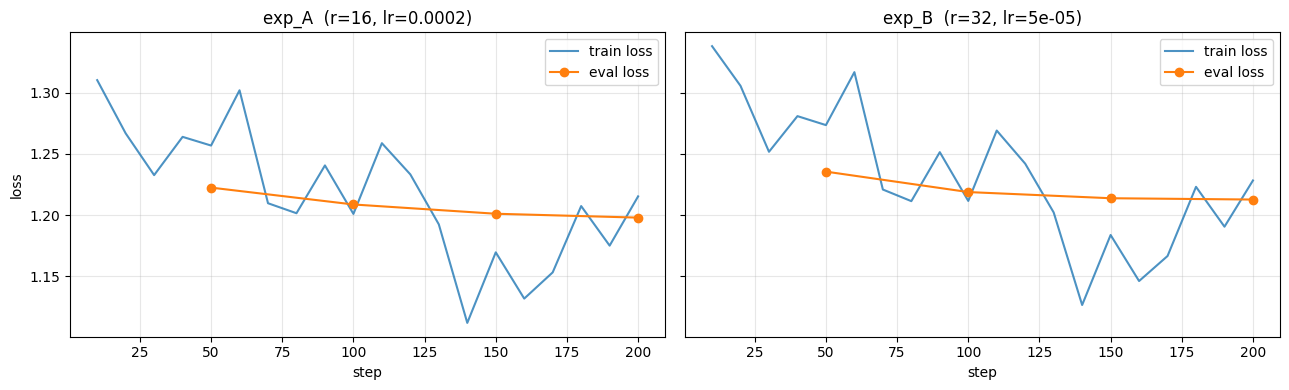

In [17]:
fig, axes = plt.subplots(1, len(experiment_results), figsize=(13, 4), sharey=True)
for ax, (run_name, res) in zip(axes, experiment_results.items()):
    ax.plot(res["train"]["step"], res["train"]["loss"], label="train loss", alpha=0.8)
    ax.plot(res["eval"]["step"], res["eval"]["eval_loss"], "o-", label="eval loss")
    ax.set_title(f"{run_name}  (r={res['cfg']['lora_r']}, lr={res['cfg']['learning_rate']})")
    ax.set_xlabel("step")
    ax.grid(alpha=0.3)
    ax.legend()
axes[0].set_ylabel("loss")
plt.tight_layout()
plt.show()

In [18]:
rows = []
for run_name, res in experiment_results.items():
    eval_losses = res["eval"]["eval_loss"].tolist()
    final_train = res["train"]["loss"].tail(5).mean()
    rows.append({
        "experiment": run_name,
        **res["cfg"],
        "train_loss (avg 5 log terakhir)": round(final_train, 4),
        "eval_loss akhir": round(eval_losses[-1], 4),
        "eval_loss terbaik": round(min(eval_losses), 4),
        "gap eval - train": round(eval_losses[-1] - final_train, 4),
        # overfitting: eval loss naik lagi > 2% dari titik terendahnya
        "overfitting": eval_losses[-1] > min(eval_losses) * 1.02,
        "durasi (menit)": round(res["minutes"], 1),
    })
summary = pd.DataFrame(rows).set_index("experiment")
display(summary)

candidates = summary[~summary["overfitting"]] if (~summary["overfitting"]).any() else summary
BEST_EXPERIMENT = candidates["eval_loss akhir"].idxmin()
BEST_CONFIG = EXPERIMENTS[BEST_EXPERIMENT]
print(f"Kombinasi terbaik: {BEST_EXPERIMENT} -> {BEST_CONFIG}")

,lora_r,lora_alpha,learning_rate,lr_scheduler_type,train_loss (avg 5 log terakhir),eval_loss akhir,eval_loss terbaik,gap eval - train,overfitting,durasi (menit)
experiment,,,,,,,,,,
exp_A,16,32,0.00020,linear,1.1766,1.1980,1.1980,0.0214,False,15.4
exp_B,32,32,0.00005,cosine,1.1910,1.2128,1.2128,0.0218,False,15.3


Kombinasi terbaik: exp_A -> {'lora_r': 16, 'lora_alpha': 32, 'learning_rate': 0.0002, 'lr_scheduler_type': 'linear'}


## 4. Training Final — 800 Steps dengan Kombinasi Terbaik

Kombinasi hyperparameter dengan *eval loss* akhir terendah (dan tanpa tanda overfitting) dilatih ulang
dari base model selama **800 steps** dengan evaluasi tiap 100 steps.

In [19]:
model, tokenizer = load_qlora_model(BEST_CONFIG["lora_r"], BEST_CONFIG["lora_alpha"])
trainer = make_trainer(model, tokenizer, "final_sft", BEST_CONFIG, max_steps=FINAL_STEPS, eval_steps=100)

torch.cuda.reset_peak_memory_stats()
trainer_stats = trainer.train()

==((====))==  Unsloth 2026.10.7: Fast Qwen2 patching. Transformers: 5.16.1.
   \\   /|    Tesla T4. Num GPUs = 2. Max memory: 14.562 GB. Platform: Linux.
O^O/ \_/ \    Torch: 2.11.0+cu128. CUDA: 7.5. CUDA Toolkit: 12.8. Triton: 3.6.0
\        /    Bfloat16 = FALSE. FA [Xformers = 0.0.35. FA2 = False]
 "-____-"     Free license: http://github.com/unslothai/unsloth
Unsloth: Fast downloading is enabled - ignore downloading bars which are red colored!


/usr/local/lib/python3.13/dist-packages/huggingface_hub/constants.py:299: FutureWarning: The `HF_HUB_ENABLE_HF_TRANSFER` environment variable is deprecated as 'hf_transfer' is not used anymore. Please use `HF_XET_HIGH_PERFORMANCE` instead to enable high performance transfer with Xet. Visit https://huggingface.co/docs/huggingface_hub/package_reference/environment_variables#hfxethighperformance for more details.
  warnings.warn(


Unsloth: Not splitting across GPUs; the model fits on cuda:0 with room to train. Pass device_map = "unsloth_balanced" to split it anyway.


Loading weights:   0%|          | 0/434 [00:00<?, ?it/s]

🦥 Unsloth: Padding-free auto-enabled, enabling faster training.


The tokenizer has new PAD/BOS/EOS tokens that differ from the model config and generation config. The model config and generation config were aligned accordingly, being updated with the tokenizer's values. Updated tokens: {'bos_token_id': None}.
==((====))==  Unsloth - 2x faster free finetuning | Num GPUs used = 1
   \\   /|    Num examples = 49,455 | Num Epochs = 1 | Total steps = 800
O^O/ \_/ \    Batch size per device = 2 | Gradient accumulation steps = 4
\        /    Data Parallel GPUs = 1 | Total batch size (2 x 4 x 1) = 8
 "-____-"     Trainable parameters = 29,933,568 of 3,115,872,256 (0.96% trained)


Unsloth: Will smartly offload gradients to save VRAM!


Step,Training Loss,Validation Loss
100,1.201055,1.212474
200,1.215201,1.196528
300,1.134908,1.185461
400,1.189061,1.177552
500,1.173051,1.168489
600,1.257385,1.161065
700,1.152207,1.157375
800,1.137326,1.155443


Unsloth: Double buffering enabled (parallel H2D + compute) for backward pass.


Steps selesai      : 800 / 800
Durasi training    : 51.8 menit
Train loss (rata2) : 1.1883
Puncak VRAM        : 5.23 GB dari 14.56 GB (tanpa OOM)


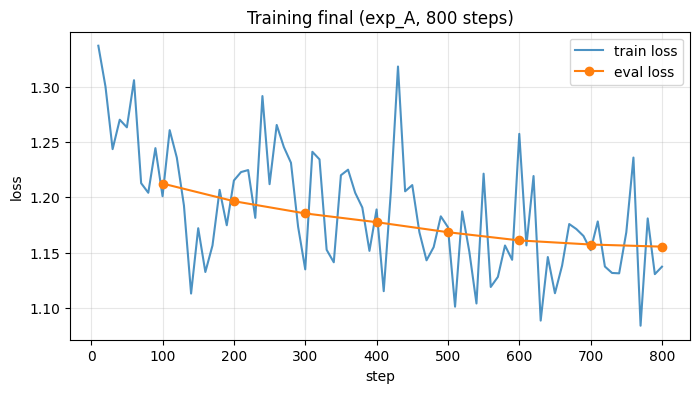

step,100,200,300,400,500,600,700,800
eval_loss,1.212474,1.196528,1.185461,1.177552,1.168489,1.161065,1.157375,1.155443


In [20]:
peak_gb = round(torch.cuda.max_memory_reserved() / 1024**3, 2)
print(f"Steps selesai      : {trainer.state.global_step} / {FINAL_STEPS}")
print(f"Durasi training    : {trainer_stats.metrics['train_runtime'] / 60:.1f} menit")
print(f"Train loss (rata2) : {trainer_stats.metrics['train_loss']:.4f}")
print(f"Puncak VRAM        : {peak_gb} GB dari {GPU_TOTAL_GB} GB (tanpa OOM)")
assert trainer.state.global_step >= 800

final_train_log, final_eval_log = loss_history(trainer)
plt.figure(figsize=(8, 4))
plt.plot(final_train_log["step"], final_train_log["loss"], label="train loss", alpha=0.8)
plt.plot(final_eval_log["step"], final_eval_log["eval_loss"], "o-", label="eval loss")
plt.title(f"Training final ({BEST_EXPERIMENT}, {FINAL_STEPS} steps)")
plt.xlabel("step")
plt.ylabel("loss")
plt.grid(alpha=0.3)
plt.legend()
plt.show()
display(final_eval_log.set_index("step").T)

## 5. Uji Inferensi Model Hasil Fine-tuning

In [21]:
FastLanguageModel.for_inference(model)
streamer = TextStreamer(tokenizer, skip_prompt=True, skip_special_tokens=True)

test_questions = [
    "Jelaskan perbedaan antara pekerja kontrak (PKWT) dan pekerja tetap (PKWTT) secara singkat.",
    "Berikan tiga tips menjaga kesehatan mental bagi pekerja kantoran.",
]
for question in test_questions:
    print(f"\n### {question}")
    messages = [{"role": "system", "content": SFT_SYSTEM_PROMPT}, {"role": "user", "content": question}]
    inputs = tokenizer.apply_chat_template(
        messages, add_generation_prompt=True, return_tensors="pt", return_dict=True
    ).to("cuda")
    _ = model.generate(**inputs, streamer=streamer, max_new_tokens=256, temperature=0.3, top_p=0.9, do_sample=True)

# Test case RAG dengan konteks PP 35/2021 halaman 18, 17, 19 (urutan sama dengan notebook RAG). Chunk lembur
# ditahan dari data latih dan tidak ada prefill: model harus membuka <think> sendiri.
TEST_QUERY = "Saya staf admin, kemarin lembur 3 jam untuk beresin laporan. Apakah saya berhak dapat uang lembur?"
pp35_pages = {d.metadata["page"]: d for d in parent_docs if d.metadata["peraturan_id"] == "PP-35-2021"}
lembur_docs = [pp35_pages[page] for page in (18, 17, 19)]
rag_test = rag_messages(TEST_QUERY, lembur_docs, target="")[:2]
inputs = tokenizer.apply_chat_template(
    rag_test, add_generation_prompt=True, return_tensors="pt", return_dict=True
).to("cuda")
output = model.generate(**inputs, max_new_tokens=512, do_sample=False)
rag_output = tokenizer.decode(output[0][inputs["input_ids"].shape[1]:], skip_special_tokens=True)
print(f"\n### [RAG] {TEST_QUERY}\n{rag_output}")
print("\nMembuka <think> sendiri:", rag_output.lstrip().startswith("<think>"))


### Jelaskan perbedaan antara pekerja kontrak (PKWT) dan pekerja tetap (PKWTT) secara singkat.


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)


Pekerja Kontrak (PKWT) adalah individu yang bekerja untuk perusahaan atau organisasi dengan waktu kerja yang terbatas atau tidak terdefinisi, biasanya dalam satu proyek atau tugas tertentu. Mereka biasanya dibayar sesuai dengan jumlah waktu yang mereka habiskan di tempat kerja, dan mereka dapat dikeluarkan dari pekerjaan mereka jika proyek selesai atau jika perusahaan memutuskan untuk tidak mempekerjakan mereka lagi.

Di sisi lain, Pekerja Tetap (PKWTT) adalah individu yang bekerja untuk perusahaan atau organisasi dengan jam kerja yang terdefinisi, gaji tetap, dan hak-hak yang ditetapkan oleh undang-undang. Mereka biasanya memiliki kesempatan untuk mengajukan pengembalian kerja, dan mereka sering memiliki hak-hak tambahan seperti hari libur, manfaat kesehatan, dan tunjangan lainnya.

Secara ringkas, PKWT bekerja untuk waktu yang terbatas atau tidak terdefinisi, sedangkan PKWTT bekerja untuk waktu yang terdefinisi, gaji tet


Both `max_new_tokens` (=256) and `max_length`(=32768) seem to have been set. `max_new_tokens` will take precedence. Please refer to the documentation for more information. (https://huggingface.co/docs/transformers/main/en/main_classes/text_generation)



### Berikan tiga tips menjaga kesehatan mental bagi pekerja kantoran.
1. Beristirahat secara teratur: Jangan lupa untuk beristirahat dari pekerjaan Anda secara teratur. Ini dapat membantu Anda menghindari stres dan kelelahan. Coba gunakan waktu istirahat 5-10 menit untuk berjalan-jalan, minum air, atau melakukan sesuatu yang menyenangkan.

2. Tetap terhubung dengan orang lain: Jangan biarkan diri Anda terisolasi selama bekerja di kantor. Hubungi teman dan keluarga Anda secara teratur, dan cari grup online atau acara lokal untuk bergabung dengan. Hal ini dapat membantu Anda merasa terhubung dan tidak terisolasi.

3. Tetap aktif fisik: Aktivitas fisik dapat membantu mengurangi stres dan meningkatkan mood. Coba lakukan olahraga ringan seperti yoga, jogging, atau berjalan-jalan sebanyak mungkin. Atau, jika Anda memiliki ruang kerja yang luas, cobalah berjalan-jalan sebanyak mungkin selama hari kerja Anda.


## 6. Push Model ke Hugging Face (`merged_16bit`)

Adapter LoRA digabung ke bobot base model lalu diunggah dalam presisi 16-bit, sehingga dapat dimuat
langsung pada tahap GRPO dan RAG.

In [22]:
def save_link(label, url, path="link_huggingface.txt"):
    """Catat tautan model di link_huggingface.txt; baris berlabel sama diganti (aman di-run ulang)."""
    lines = open(path).read().splitlines() if os.path.exists(path) else []
    lines = [line for line in lines if line.strip() and not line.startswith(label)] + [f"{label}: {url}"]
    with open(path, "w") as f:
        f.write("\n".join(lines) + "\n")
    print(open(path).read())


model.push_to_hub_merged(SFT_REPO, tokenizer, save_method="merged_16bit", token=HF_TOKEN)
SFT_URL = f"https://huggingface.co/{SFT_REPO}"
print("Model SFT tersedia di:", SFT_URL)

save_link("Model Fine-tuning (SFT, Kriteria 1)", SFT_URL)

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.
Unsloth: Restored added_tokens_decoder metadata in Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT/tokenizer_config.json.
No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub._upload_pipeline|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.


Found HuggingFace hub cache directory: /root/.cache/huggingface/hub


Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 1 files:   0%|          | 0/1 [00:00<?, ?it/s]

No files have been modified since last commit. Skipping to prevent empty commit.
[huggingface_hub.hf_api|WARNING]No files have been modified since last commit. Skipping to prevent empty commit.


...



Unsloth: Merging weights into 16bit:  50%|█████     | 1/2 [01:20<01:20, 80.69s/it]

Processing Files (0 / 0): |          |  0.00B /  0.00B            

New Data Upload: |          |  0.00B /  0.00B            



Unsloth: Merging weights into 16bit: 100%|██████████| 2/2 [01:56<00:00, 58.05s/it]


Unsloth: Merge process complete. Saved to `/kaggle/working/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT`
Model SFT tersedia di: https://huggingface.co/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT
Model Fine-tuning (SFT, Kriteria 1): https://huggingface.co/Fepriyadi/Qwen2.5-3B-Instruct-Alpaca-ID-SFT



## Kesimpulan

- Dataset Alpaca Indonesia di-*mapping* ke ChatML dengan `Dataset.map`, contoh baris sebelum/sesudah ditampilkan.
- Contoh kerja RAG dibuat kode dari 4 PDF UU/PP (tanpa teacher model): kutip pasal → bandingkan angka →
  simpulkan, diawali `<think>`. Chunk lembur ditahan sehingga test case RAG tetap uji yang jujur.
- Model dimuat dengan QLoRA (4-bit NF4 + double quantization); LoRA terpasang di Multi-Head Attention
  dan Feed Forward Network.
- Dua eksperimen hyperparameter dibandingkan lewat kurva train/eval loss; kombinasi terbaik dilatih
  800 steps tanpa OOM.
- Model hasil merge 16-bit di-*push* ke Hugging Face dan tautannya dicatat di `link_huggingface.txt`.

**Langkah berikutnya:** notebook `GRPO_submission_PGABL_FepriyadiH.ipynb` memuat `SFT_REPO` dan melatih penalaran `<think>`.